# Kenya Loan Portfolio Risk Analysis: 

**Data note:** all data here is *simulated* 

`Load messy data  ->  Clean it  ->  Add useful columns  ->  Calculate risk KPIs  ->  Compare groups  ->  Draw charts  ->  Explain what it means`

## Step 0: Import the tools


In [1]:
import pandas as pd                  # pandas = tables of data; we nickname it "pd" so we type less
import numpy as np                   # numpy = maths helpers; nickname "np"
import matplotlib.pyplot as plt      # matplotlib = charts; nickname "plt"

pd.set_option("display.max_columns", 40)               # show up to 40 columns when printing a table
pd.set_option("display.float_format", "{:,.1f}".format) # show numbers with commas and 1 decimal place

## Step 1: Load the data and inspect it

We load the file, then ask five questions: *How big is it? What does it look like? What types are the columns? What is missing? Are there duplicates?*

In [5]:
# read_csv loads a CSV file into a table. "raw" is the variable name we give it.
# keep_default_na=False + na_values=[""] means ONLY truly empty cells count as missing. Without this, pandas would treat the
# word "None" (our label for "no collateral") as missing, and those loans would silently disappear from the results!
raw = pd.read_csv(r"C:\Users\user\Downloads\kenya-loan-portfolio-analysis (1)\data\raw_loans.csv",
                  keep_default_na=False, na_values=[""])
print("Rows and columns:", raw.shape)      # .shape gives (number of rows, number of columns)
raw.head()                                 # .head() shows the first 5 rows so we can eyeball the data

Rows and columns: (5025, 20)


,loan_id,customer_id,disbursement_date,county,gender,age,business_sector,product,loan_amount_kes,term_months,interest_rate_flat_pct,monthly_income_kes,crb_score,collateral_type,repayment_channel,installments_paid,outstanding_principal_kes,days_past_due,risk_class,loan_status
0,KE-LN-002949,CUST-04192,16/11/2024,Nyeri,M,37,Retail (Duka / Mama Mboga),Biashara Loan,52000,6,25.1,"34,000.0",NaN,None,M-Pesa Paybill,6,0,0,Normal,Closed
1,KE-LN-004265,CUST-02877,2025-05-24,Bungoma,Male,32,Hospitality & Food,Asset Finance,419000,48,17.2,"50,000.0",545.0,Logbook,M-Pesa Paybill,4,384083,0,Normal,Active
2,KE-LN-001403,CUST-02366,2024-02-16,Kiambu,Female,34,Transport (Boda Boda / Matatu),Biashara Loan,46000,18,19.5,"119,000.0",566.0,None,M-Pesa Paybill,18,0,0,Normal,Closed
3,KE-LN-001712,CUST-03929,2024-04-13,Kiambu,Female,29,Private Education,Biashara Loan,103000,6,19.4,"95,500.0",540.0,None,Cash at Branch,6,0,0,Normal,Closed
4,KE-LN-002888,CUST-02198,2024-11-05,Nairobi,F,42,Transport (Boda Boda / Matatu),Asset Finance,615000,24,16.2,"24,000.0",654.0,Logbook,Cash at Branch,10,358750,0,Normal,Active


In [6]:
raw.info()   # .info() lists every column, how many values are NOT empty, and its data type (int, float, object = text)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5025 entries, 0 to 5024
Data columns (total 20 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   loan_id                    5025 non-null   object 
 1   customer_id                5025 non-null   object 
 2   disbursement_date          5025 non-null   object 
 3   county                     5025 non-null   object 
 4   gender                     5025 non-null   object 
 5   age                        5025 non-null   int64  
 6   business_sector            5025 non-null   object 
 7   product                    5025 non-null   object 
 8   loan_amount_kes            5025 non-null   int64  
 9   term_months                5025 non-null   int64  
 10  interest_rate_flat_pct     5025 non-null   float64
 11  monthly_income_kes         4810 non-null   float64
 12  crb_score                  4728 non-null   float64
 13  collateral_type            5025 non-null   objec

In [7]:
raw.isna().sum()   # .isna() marks empty cells as True; .sum() counts the True values per column -> how many missing

loan_id                        0
customer_id                    0
disbursement_date              0
county                         0
gender                         0
age                            0
business_sector                0
product                        0
loan_amount_kes                0
term_months                    0
interest_rate_flat_pct         0
monthly_income_kes           215
crb_score                    297
collateral_type                0
repayment_channel              0
installments_paid              0
outstanding_principal_kes      0
days_past_due                  0
risk_class                     0
loan_status                    0
dtype: int64

In [8]:
print("Duplicate rows:", raw.duplicated().sum())   # .duplicated() flags rows that are exact copies of an earlier row
print()
print(raw["county"].value_counts().head(12))        # .value_counts() counts how often each value appears: look for spelling problems

Duplicate rows: 25

county
Nairobi        832
Nakuru         383
Kiambu         368
Kisumu         294
Mombasa        288
Uasin Gishu    285
Machakos       241
Kakamega       223
Meru           217
Bungoma        210
Kisii          192
Nyeri          188
Name: count, dtype: int64


pandas automatically treats some words (such as `None`, `NA` and `null`) as missing values. Our collateral column uses the word "None" to mean *no collateral*, so we told `read_csv` not to do that. 
- `monthly_income_kes` and `crb_score` have missing values.
- There are duplicate rows.
- The same county appears in different spellings (for example `Nairobi`, `NAIROBI`, `Nairobi `). Python treats these as *different* places, which would split our results.

## Step 2: Clean the data

We fix one problem at a time and **check the result after each fix**. We also work on a copy (`df`) so the original `raw` stays untouched.

### 2.1 Remove duplicate rows

In [9]:
df = raw.drop_duplicates().copy()   # drop_duplicates() removes exact repeat rows; .copy() makes a separate table so we never change "raw"
print("Rows before:", len(raw), "| Rows after:", len(df))   # len() counts rows; we expect 25 fewer

Rows before: 5025 | Rows after: 5000


### 2.2 Standardise county names

In [10]:
print("Before:", df["county"].nunique(), "different county spellings")   # .nunique() = number of distinct values (we expect 18 real counties)
df["county"] = df["county"].str.strip().str.title()   # .str.strip() removes spaces at the ends; .str.title() makes "NAIROBI" -> "Nairobi"
print("After :", df["county"].nunique(), "counties")

Before: 67 different county spellings
After : 18 counties


### 2.3 Standardise gender labels

In [11]:
print(df["gender"].value_counts())   # we see F, female, Female, M, male... all meaning the same thing

gender
Female    2230
Male      2032
F          220
female     181
male       175
M          162
Name: count, dtype: int64


In [12]:
# Step by step: strip spaces -> make lowercase -> keep only the first letter ("f" or "m") -> translate with a dictionary
df["gender"] = df["gender"].str.strip().str.lower().str[0].map({"f": "Female", "m": "Male"})
print(df["gender"].value_counts())

gender
Female    2631
Male      2369
Name: count, dtype: int64


### 2.4 Fix the mixed date formats

Some dates are `2024-03-05` (year-month-day) and some are `05/03/2024` (day/month/year). If we let Python guess, it may read `05/03/2024` as 3 May instead of 5 March. So we **tell it the format** for the slash dates.

In [13]:
has_slash = df["disbursement_date"].str.contains("/")     # True for rows written like 05/03/2024
print("Dates written with slashes:", has_slash.sum())

# For slash rows only: read them as day/month/year, then write them back in year-month-day text
df.loc[has_slash, "disbursement_date"] = (
    pd.to_datetime(df.loc[has_slash, "disbursement_date"], format="%d/%m/%Y").dt.strftime("%Y-%m-%d")
)
df["disbursement_date"] = pd.to_datetime(df["disbursement_date"])   # now every row is in one format, convert the whole column to real dates
df["disbursement_date"].dtype                                        # should say datetime64: a proper date column

Dates written with slashes: 616


dtype('<M8[ns]')

### 2.5 Missing income: fill it

We fill missing income with the **median income of the same sector** (a trader is more like other traders than like a teacher). 

In [14]:
df["income_imputed"] = df["monthly_income_kes"].isna()   # True where income was missing: this is our "we guessed this" flag

sector_median = df.groupby("business_sector")["monthly_income_kes"].transform("median")   # for every row, the median income of ITS sector
df["monthly_income_kes"] = df["monthly_income_kes"].fillna(sector_median)                # fillna() replaces empty cells with that sector median

print("Rows filled:", df["income_imputed"].sum(), "| Missing income now:", df["monthly_income_kes"].isna().sum())

Rows filled: 215 | Missing income now: 0


### 2.6 Missing CRB score: leave it empty

We do **not** invent credit scores. A missing score is information in itself (the person may have no credit history), so we will give them their own group later.

In [15]:
print("Missing CRB scores:", df["crb_score"].isna().sum())   # we only count them; no fix needed

Missing CRB scores: 295


## Step 3: Create new columns (feature engineering)

Raw columns rarely answer business questions directly. We build columns that do.

### 3.1 Monthly installment and repayment burden

The lender charges a **flat** interest rate, so the total repayable is `amount x (1 + rate x years)`, split into equal monthly installments.

*Worked example:* KES 100,000 at 24% flat for 12 months -> `100,000 x (1 + 0.24 x 12/12) / 12 = KES 10,333` per month.

**Repayment burden** = installment / monthly income. If someone earns KES 40,000 and pays KES 10,333, the burden is about 26%.

In [16]:
# Same formula as the worked example above, applied to every row at once (pandas does the arithmetic row by row)
df["installment_kes"] = df["loan_amount_kes"] * (1 + df["interest_rate_flat_pct"] / 100 * df["term_months"] / 12) / df["term_months"]
df["installment_to_income"] = df["installment_kes"] / df["monthly_income_kes"]   # what share of income goes to this loan each month
df[["loan_amount_kes", "interest_rate_flat_pct", "term_months", "installment_kes", "monthly_income_kes", "installment_to_income"]].head()

,loan_amount_kes,interest_rate_flat_pct,term_months,installment_kes,monthly_income_kes,installment_to_income
0,52000,25.1,6,"9,754.3","34,000.0",0.3
1,419000,17.2,48,"14,734.8","50,000.0",0.3
2,46000,19.5,18,"3,303.1","119,000.0",0.0
3,103000,19.4,6,"18,831.8","95,500.0",0.2
4,615000,16.2,24,"33,927.5","24,000.0",1.4


### 3.2 Turning numbers into groups with `pd.cut`

`pd.cut(values, bins, labels)` sorts numbers into ranges. First a tiny example, then the real columns.

In [17]:
ages = pd.Series([19, 25, 34, 52])                                       # a tiny practice list
pd.cut(ages, bins=[0, 24, 40, 100], labels=["Young", "Middle", "Older"]) # 0-24 -> Young, 25-40 -> Middle, 41-100 -> Older

0     Young
1    Middle
2    Middle
3     Older
dtype: category
Categories (3, object): ['Young' < 'Middle' < 'Older']

In [18]:
# CRB score bands. Scores that are missing stay empty after pd.cut, so we label them explicitly ("No CRB score")
df["score_band"] = pd.cut(df["crb_score"], bins=[0, 500, 575, 650, 725, 900],
                          labels=["300-500", "501-575", "576-650", "651-725", "726-850"]).astype(object).fillna("No CRB score")

# Repayment burden bands: under 15%, 15-25%, 25-35%, over 35% of income
df["burden_band"] = pd.cut(df["installment_to_income"], bins=[0, .15, .25, .35, 10],
                           labels=["Under 15%", "15-25%", "25-35%", "Over 35%"])

df["score_band"].value_counts()   # check the groups look sensible

score_band
576-650         1539
501-575         1109
651-725         1050
726-850          524
300-500          483
No CRB score     295
Name: count, dtype: int64

### 3.3 Risk flags

Credit-risk definitions use **days past due (DPD)**:
- **PAR30** = loan is more than 30 days late. **NPL** (non-performing loan) = more than 90 days late.

A comparison like `df["days_past_due"] > 90` gives True/False for every row.

In [19]:
df["is_npl"] = df["days_past_due"] > 90     # True if the loan is more than 90 days late
df["is_par30"] = df["days_past_due"] > 30   # True if more than 30 days late

df["disbursement_quarter"] = df["disbursement_date"].dt.to_period("Q").astype(str)   # e.g. 2024Q1: used later for cohort (vintage) analysis

active = df[df["loan_status"] == "Active"].copy()   # "Active" loans still have money outstanding; repaid ("Closed") loans are not part of today's risk
print("All loans:", len(df), "| Active loans:", len(active))

All loans: 5000 | Active loans: 2600


## Step 4: Portfolio KPIs

Lenders measure risk **by money, not by number of loans**, because one big bad loan matters more than one small one.

- **PAR30 %** = (outstanding balance of loans >30 days late) / (total outstanding balance)
- **NPL ratio %** = (outstanding balance of loans >90 days late) / (total outstanding balance)

In [20]:
total_outstanding = active["outstanding_principal_kes"].sum()                                  # all the money still owed to the lender
par30_balance = active.loc[active["is_par30"], "outstanding_principal_kes"].sum()              # .loc[filter, column]: only the late loans' balances
npl_balance = active.loc[active["is_npl"], "outstanding_principal_kes"].sum()                  # only the >90 days late balances

print(f"Total outstanding : KES {total_outstanding/1e6:,.1f} million")   # /1e6 converts shillings to millions
print(f"PAR30             : {par30_balance/total_outstanding*100:.1f}%")  # part / whole x 100 = percentage
print(f"NPL ratio         : {npl_balance/total_outstanding*100:.1f}%")

Total outstanding : KES 296.8 million
PAR30             : 20.3%
NPL ratio         : 15.7%


### Provisions (money set aside for expected losses)

The worse a loan's risk class, the larger the share we set aside. These rates are **illustrative**, roughly following Central Bank of Kenya classes.

In [21]:
provision_rates = {"Normal": 0.01, "Watch": 0.03, "Substandard": 0.20, "Doubtful": 0.50, "Loss": 1.00}   # dictionary: class -> % to set aside

active["provision_kes"] = active["outstanding_principal_kes"] * active["risk_class"].map(provision_rates)   # .map() looks up each row's class in the dictionary

total_provisions = active["provision_kes"].sum()
print(f"Estimated provisions: KES {total_provisions/1e6:,.1f} million = {total_provisions/total_outstanding*100:.1f}% of outstanding")
print(f"Compare: NPL ratio is {npl_balance/total_outstanding*100:.1f}% -> provisions cover less than the NPL ratio, a gap to flag")

Estimated provisions: KES 34.4 million = 11.6% of outstanding
Compare: NPL ratio is 15.7% -> provisions cover less than the NPL ratio, a gap to flag


## Step 5: Compare groups with `groupby` 

`groupby` means: **split the table into groups, calculate something for each group, put the results back together.** I

In [22]:
toy = pd.DataFrame({"sector": ["Retail", "Retail", "Farming", "Farming"],
                    "balance": [100, 300, 200, 200],
                    "late_balance": [0, 150, 100, 0]})      # 4 made-up loans

summary = toy.groupby("sector").agg(loans=("balance", "count"),            # how many loans in each sector
                                    balance=("balance", "sum"),            # total balance per sector
                                    late_balance=("late_balance", "sum"))  # total late balance per sector
summary["late_pct"] = summary["late_balance"] / summary["balance"] * 100   # then a ratio, exactly like our NPL ratio
summary

,loans,balance,late_balance,late_pct
sector,,,,
Farming,2,400,100,25.0
Retail,2,400,150,37.5


Now the same idea on the real portfolio. First we prepare two helper columns that hold the balance **only when the loan is late**:

In [23]:
active["npl_balance"] = np.where(active["is_npl"], active["outstanding_principal_kes"], 0)     # np.where(condition, if True, if False)
active["par30_balance"] = np.where(active["is_par30"], active["outstanding_principal_kes"], 0)
active[["loan_id", "outstanding_principal_kes", "days_past_due", "npl_balance", "par30_balance"]].sort_values("days_past_due", ascending=False).head()

,loan_id,outstanding_principal_kes,days_past_due,npl_balance,par30_balance
3341,KE-LN-000042,149000,938,149000,149000
3500,KE-LN-000008,7333,928,7333,7333
1414,KE-LN-000102,30000,905,30000,30000
4446,KE-LN-000011,56000,896,56000,56000
5013,KE-LN-000125,14000,894,14000,14000


In [24]:
def risk_by(column):
    """Return a risk table: one row per group in `column` (for example business_sector)."""
    table = active.groupby(column, observed=True).agg(
        active_loans=("loan_id", "count"),                          # number of active loans
        outstanding_kes_m=("outstanding_principal_kes", "sum"),     # money outstanding
        npl_balance=("npl_balance", "sum"),                         # money more than 90 days late
        par30_balance=("par30_balance", "sum"),                     # money more than 30 days late
    )
    table["outstanding_kes_m"] = table["outstanding_kes_m"] / 1e6                                   # shillings -> millions
    table["npl_ratio_pct"] = table["npl_balance"] / (table["outstanding_kes_m"] * 1e6) * 100        # NPL ratio for each group
    table["par30_pct"] = table["par30_balance"] / (table["outstanding_kes_m"] * 1e6) * 100
    # default rate: % of ALL loans ever made in the group (including repaid ones) that are now >90 days late
    table["default_rate_pct"] = df.groupby(column, observed=True)["is_npl"].mean() * 100
    return table[["active_loans", "outstanding_kes_m", "npl_ratio_pct", "par30_pct", "default_rate_pct"]]

A function packages steps so we can reuse them. Now one line gives us a full analysis for any column.

In [25]:
risk_by("business_sector").sort_values("npl_ratio_pct", ascending=False)

,active_loans,outstanding_kes_m,npl_ratio_pct,par30_pct,default_rate_pct
business_sector,,,,,
Agriculture,339,17.4,30.7,37.7,9.0
Services (Salon / Barber / Cyber),262,15.7,23.8,25.9,6.6
Retail (Duka / Mama Mboga),704,42.8,22.6,26.4,8.2
Transport (Boda Boda / Matatu),531,133.5,15.0,20.4,7.7
Salaried Employee,156,5.2,12.4,18.8,1.5
Jua Kali / Manufacturing,266,33.8,9.4,14.9,5.9
Hospitality & Food,242,31.9,9.1,11.3,4.9
Private Education,100,16.4,5.6,8.5,2.0


In [26]:
risk_by("score_band").sort_values("npl_ratio_pct", ascending=False)

,active_loans,outstanding_kes_m,npl_ratio_pct,par30_pct,default_rate_pct
score_band,,,,,
300-500,297,33.4,33.4,45.6,19.7
501-575,593,70.8,25.2,28.2,9.4
576-650,796,88.8,11.7,14.9,5.3
No CRB score,156,17.3,10.1,11.1,4.7
651-725,520,59.6,8.3,14.6,3.0
726-850,238,27.0,1.4,4.2,1.3


In [27]:
risk_by("burden_band")

,active_loans,outstanding_kes_m,npl_ratio_pct,par30_pct,default_rate_pct
burden_band,,,,,
Under 15%,907,41.6,7.1,10.2,3.7
15-25%,593,53.1,7.6,12.3,4.7
25-35%,372,42.7,11.4,15.8,6.9
Over 35%,728,159.4,21.7,26.7,12.2


In [28]:
risk_by("county").sort_values("npl_ratio_pct", ascending=False).head(5)   # .head(5) = the five worst counties

,active_loans,outstanding_kes_m,npl_ratio_pct,par30_pct,default_rate_pct
county,,,,,
Kitui,82,8.7,32.2,42.1,10.1
Kisii,118,11.6,27.7,30.3,7.3
Nyeri,106,13.1,24.8,25.6,5.8
Mombasa,177,20.0,21.1,27.0,6.8
Bungoma,122,15.0,20.1,25.6,9.7


In [29]:
risk_by("collateral_type").sort_values("npl_ratio_pct", ascending=False)

,active_loans,outstanding_kes_m,npl_ratio_pct,par30_pct,default_rate_pct
collateral_type,,,,,
Personal Guarantor,515,32.7,25.2,32.2,8.5
Group Guarantee,168,4.5,24.0,27.0,5.5
None,657,40.4,22.5,26.0,8.2
Chattels / Stock,388,26.7,20.9,24.0,6.7
Title Deed,196,11.0,16.4,22.4,5.1
Logbook,538,176.5,11.4,16.0,6.3
Payroll Check-off,138,5.0,11.2,17.8,1.0


### Why two different measures?
- **NPL ratio** looks only at loans still outstanding today. Good loans that have been fully repaid disappear from it, which makes old groups look worse than they were.
- **Default rate** looks at *every loan ever made* in a group, so it compares fairly. Use it for cohorts and long-running comparisons.


## Step 6: Charts

 We colour bars **red if the group is worse than the portfolio average** and navy otherwise.

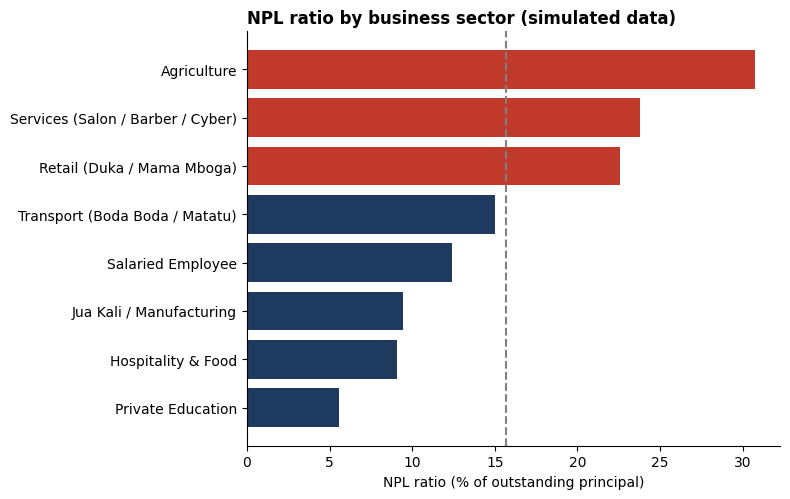

In [30]:
portfolio_npl = npl_balance / total_outstanding * 100     # the portfolio average NPL ratio, for the dashed line

def bar_chart(table, title):
    t = table.sort_values("npl_ratio_pct")                                         # sort so the biggest bar ends up at the top
    colours = ["#C0392B" if v > portfolio_npl else "#1F3A5F" for v in t["npl_ratio_pct"]]   # red if above average, else navy
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(t) + 1.5))                       # make a canvas; height grows with the number of bars
    ax.barh(t.index.astype(str), t["npl_ratio_pct"], color=colours)                # barh = horizontal bars: names on the y-axis
    ax.axvline(portfolio_npl, color="grey", linestyle="--")                        # dashed vertical line at the portfolio average
    ax.set_xlabel("NPL ratio (% of outstanding principal)")                        # axis label
    ax.set_title(title, loc="left", fontweight="bold")                             # chart title on the left
    for spine in ["top", "right"]: ax.spines[spine].set_visible(False)             # remove the box lines for a cleaner look
    plt.tight_layout(); plt.show()                                                 # fix spacing, then display

bar_chart(risk_by("business_sector"), "NPL ratio by business sector (simulated data)")

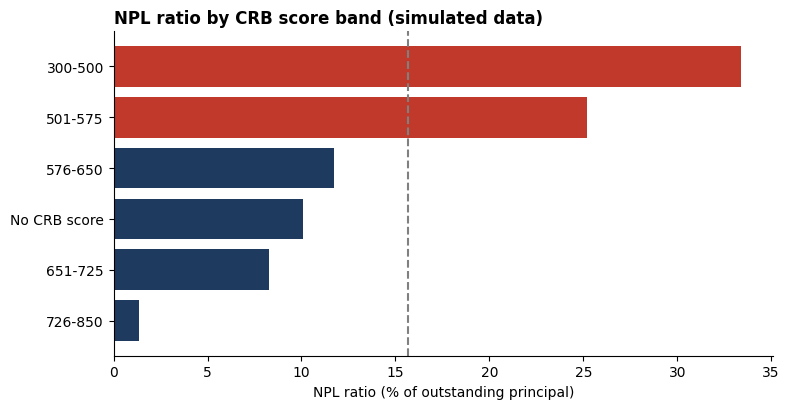

In [31]:
bar_chart(risk_by("score_band"), "NPL ratio by CRB score band (simulated data)")

### Cohort (vintage) chart

We group loans by the quarter they were made and plot the **default rate on all loans originated**. Recent cohorts look good only because they have not had time to go bad yet. *Time is a hidden variable.*

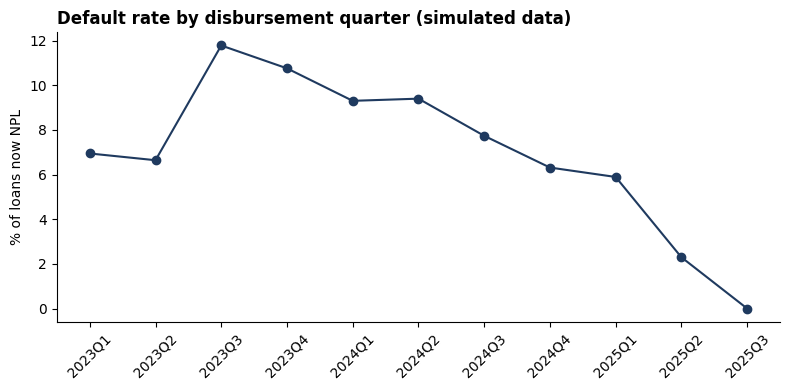

In [32]:
vintage = df.groupby("disbursement_quarter")["is_npl"].mean() * 100   # for each quarter: share of loans that are now >90 days late

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(vintage.index, vintage.values, marker="o", color="#1F3A5F")   # line with a dot at each quarter
plt.xticks(rotation=45)                                               # tilt quarter labels so they do not overlap
ax.set_ylabel("% of loans now NPL")
ax.set_title("Default rate by disbursement quarter (simulated data)", loc="left", fontweight="bold")
for spine in ["top", "right"]: ax.spines[spine].set_visible(False)
plt.tight_layout(); plt.show()